<a href="https://colab.research.google.com/github/arturdiel/unijui-prog-ciencia-de-dados/blob/main/projeto-integrador-2/analise_acidentes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Acidentes de trânsito em Porto Alegre: dá para prever se houve vítima?
**Grupo**: DataCore - Artur Diel, Gabriel Schiavo, Lucas Zimmermann, Vitor Mankowski


## 1. Obtenção dos dados
Os dados são lidos direto da URL do portal de dados abertos da Prefeitura, então o notebook roda sem anexar arquivo.

In [ ]:
import pandas as pd

In [ ]:
csv_url = 'https://dadosabertos.poa.br/dataset/d6cfbe48-ee1f-450f-87f5-9426f6a09328/resource/b56f8123-716a-4893-9348-23945f1ea1b9/download/cat_acidentes.csv'

df = pd.read_csv(csv_url, sep=";")

## 2. Inspeção inicial
Tamanho da tabela, tipos de dados e valores vazios por coluna.

In [ ]:
print(f"linhas: {df.shape[0]}")
print(f"colunas: {df.shape[1]}")

print(df.head())

print("Tipos de dados de cada coluna")
print(df.dtypes)

print("Valores vazios em cada coluna:")
print(df.isnull().sum())

linhas: 87323
colunas: 34
         data_extracao  predial1  queda_arr                 data  feridos  \
0  2026-10-01 01:34:27    2596.0        0.0  2021-01-02 00:00:00        6   
1  2026-10-01 01:34:27    3659.0        0.0  2021-01-03 00:00:00        1   
2  2026-10-01 01:34:27       0.0        0.0  2021-01-03 00:00:00        1   
3  2026-10-01 01:34:27    4879.0        0.0  2021-01-04 00:00:00        1   
4  2026-10-01 01:34:27    2500.0        0.0  2021-01-03 00:00:00        1   

   feridos_gr  mortes  morte_post  fatais  auto  ...  longitude   latitude  \
0           0       0           0       0     3  ... -51.119179 -30.014936   
1           0       0           0       0     1  ... -51.157411 -30.162425   
2           0       0           0       0     1  ... -51.195553 -29.975734   
3           0       0           0       0     0  ... -51.097502 -30.012522   
4           0       0           0       0     1  ... -51.229493 -30.049345   

                             log1  log2   

## 3. Limpeza
Removemos colunas que não serão usadas, linhas com valores vazios (principalmente sem hora), datas impossíveis (ano > 2026) e acidentes com tipo "NAO CADASTRADO". A contagem de linhas é mostrada a cada passo.

In [ ]:
linhas_antes = df.shape[0]

df['data'] = pd.to_datetime(df['data'])
df['ano'] = df['data'].dt.year

colunas_descartadas = ['data_extracao', 'idacidente', 'predial1', 'log1', 'log2', 'consorcio', 'longitude', 'latitude', 'queda_arr', 'outro']
df = df[df.columns.difference(colunas_descartadas)]

df = df.dropna()
print(f'depois de remover os sem hora: {df.shape[0]}')

df = df[df["ano"] <= 2026]
print(f"depois de remover as datas impossíveis: {df.shape[0]}")

df = df[df["tipo_acid"] != "NAO CADASTRADO"].copy()
print(f"depois de remover os NAO CADASTRADO: {df.shape[0]}")

print(f"linhas antes: {linhas_antes}")
print(f"linhas depois: {df.shape[0]}")
print(f"colunas depois: {df.shape[1]}")
print(df.isnull().sum())

depois de remover os sem hora: 86476
depois de remover as datas impossíveis: 86472
depois de remover os NAO CADASTRADO: 83948
linhas antes: 87323
linhas depois: 83948
colunas depois: 25
ano           0
auto          0
bicicleta     0
caminhao      0
carroca       0
cont_vit      0
data          0
dia_sem       0
fatais        0
feridos       0
feridos_gr    0
hora          0
lotacao       0
morte_post    0
mortes        0
moto          0
noite_dia     0
onibus_int    0
onibus_met    0
onibus_urb    0
patinete      0
regiao        0
taxi          0
tipo_acid     0
ups           0
dtype: int64


## 4. Novas colunas
Criamos `noite` (1 = noite), `fim_de_semana` (1 = sábado ou domingo) e `hora_cheia` (0 a 23).

In [ ]:
# 1 quando noite_dia é NOITE e 0 quando é DIA
noite = []
for turno in df["noite_dia"]:
    if turno == "NOITE":
        noite.append(1)
    else:
        noite.append(0)
df["noite"] = noite

# fim_de_semana 1 para sábado ou domingo e 0 para a semana
fim_de_semana = []
for dia in df["dia_sem"]:
    if dia == "SÁBADO" or dia == "DOMINGO":
        fim_de_semana.append(1)
    else:
        fim_de_semana.append(0)
df["fim_de_semana"] = fim_de_semana

# conversao para hora cheia
hora_cheia = []
for hora in df["hora"]:
    hora_cheia.append(int(hora[:2]))
df["hora_cheia"] = hora_cheia

print("acidentes à noite:", df["noite"].sum())
print("acidentes no fim de semana:", df["fim_de_semana"].sum())
print("menor hora:", df["hora_cheia"].min())
print("maior hora:", df["hora_cheia"].max())
print(f"colunas: {df.shape[1]}")
print(df[["noite_dia", "noite", "dia_sem", "fim_de_semana", "hora", "hora_cheia"]].head())

acidentes à noite: 23668
acidentes no fim de semana: 15929
menor hora: 0
maior hora: 23
colunas: 28
  noite_dia  noite        dia_sem  fim_de_semana              hora  hora_cheia
0       DIA      0         SÁBADO              1  12:30:00.0000000          12
1       DIA      0        DOMINGO              1  12:40:00.0000000          12
2     NOITE      1        DOMINGO              1  21:00:00.0000000          21
3       DIA      0  SEGUNDA-FEIRA              0  07:30:00.0000000           7
4       DIA      0        DOMINGO              1  11:00:00.0000000          11


## 5. Alvo (y) e características (X)
- **y (`vitima`)**: 1 se houve algum ferido ou morto, 0 caso contrário.
- **X**: só os veículos envolvidos, `noite` e `fim_de_semana`.

`feridos`, `mortes`, `cont_vit` e similares ficam **fora do X** porque o alvo é calculado a partir delas (daria a resposta ao modelo).

In [ ]:
import matplotlib.pyplot as plt

df["vitima"] = ((df["feridos"] + df["feridos_gr"] + df["mortes"]
                 + df["morte_post"] + df["fatais"]) > 0).astype(int)

veiculos = ["auto", "taxi", "lotacao", "onibus_urb", "onibus_met", "onibus_int",
            "caminhao", "moto", "carroca", "bicicleta", "patinete"]
X = df[veiculos + ["noite", "fim_de_semana"]]
y = df["vitima"]

print(X.shape, y.shape)

(83948, 13) (83948,)


### 5.1 Verificação: por que `cont_vit` e `ups` ficam fora do X
Se essas colunas já "contêm" a resposta, usá-las no modelo seria vazamento de informação. Para conferir, comparamos cada uma com o alvo `vitima`.

In [ ]:
# Verifica se cont_vit é praticamente igual ao alvo (se for, é vazamento e fica fora do X)
print(((df["cont_vit"] > 0).astype(int) == df["vitima"]).mean())

0.9999880878639158


## 6. Análise exploratória
Para cada pergunta, uma tabela e um gráfico. Nas perguntas 3 a 7 calculamos a **% de acidentes com vítima** em cada grupo (percentual, para comparar grupos de tamanhos diferentes).

### 6.1 Acidentes com e sem vítima

sem vitima: 54307 acidentes (64.7%)
com vitima: 29641 acidentes (35.3%)


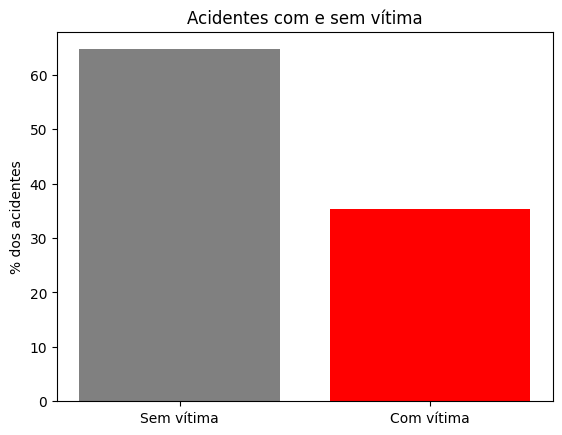

In [ ]:
# contando os acidentes com e sem vítima
total = df.shape[0]
sem_vitima = df[df["vitima"] == 0].shape[0]
com_vitima = df[df["vitima"] == 1].shape[0]

# transformando em porcentagem
pct_sem_vitima = round(sem_vitima / total * 100, 1)
pct_com_vitima = round(com_vitima / total * 100, 1)

print(f"sem vitima: {sem_vitima} acidentes ({pct_sem_vitima}%)")
print(f"com vitima: {com_vitima} acidentes ({pct_com_vitima}%)")

plt.bar(["Sem vítima", "Com vítima"], [pct_sem_vitima, pct_com_vitima], color=["gray", "red"])
plt.title("Acidentes com e sem vítima")
plt.ylabel("% dos acidentes")
plt.show()

### 6.2 Porcentagem com vítima por tipo de veículo
Considera os acidentes em que aquele veículo se envolveu.

auto: 76246 acidentes, 30.7% com vitima
taxi: 909 acidentes, 12.7% com vitima
lotacao: 492 acidentes, 21.5% com vitima
onibus_urb: 2915 acidentes, 38.0% com vitima
onibus_met: 422 acidentes, 44.3% com vitima
onibus_int: 802 acidentes, 27.6% com vitima
caminhao: 6734 acidentes, 13.4% com vitima
moto: 24771 acidentes, 76.6% com vitima
carroca: 18 acidentes, 77.8% com vitima
bicicleta: 1525 acidentes, 90.4% com vitima
patinete: 66 acidentes, 80.3% com vitima


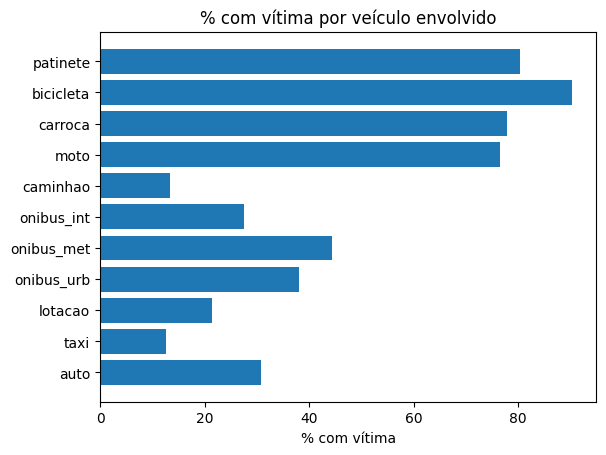

In [ ]:
# para cada veículo, os acidentes em que ele se envolveu e a % deles com vítima
porcentagens = []
for veiculo in veiculos:
    acidentes_com_veiculo = df[df[veiculo] > 0]
    quantidade = acidentes_com_veiculo.shape[0]
    pct = round(acidentes_com_veiculo["vitima"].mean() * 100, 1)
    porcentagens.append(pct)
    print(f"{veiculo}: {quantidade} acidentes, {pct}% com vitima")

plt.barh(veiculos, porcentagens)
plt.title("% com vítima por veículo envolvido")
plt.xlabel("% com vítima")
plt.show()

### 6.3 Dia x noite

noite_dia
DIA      31.5
NOITE    45.0
Name: vitima, dtype: float64


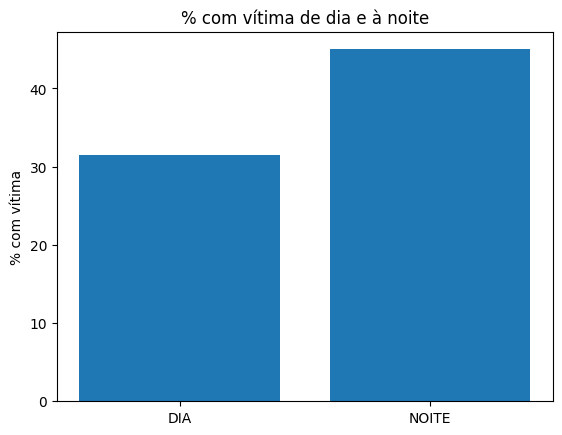

In [ ]:
pct_turno = df.groupby("noite_dia")["vitima"].mean() * 100
pct_turno = pct_turno.round(1)
print(pct_turno)

plt.bar(pct_turno.index, pct_turno.values)
plt.title("% com vítima de dia e à noite")
plt.ylabel("% com vítima")
plt.show()

### 6.4 Fim de semana e dia da semana

fim_de_semana
0    33.6
1    42.6
Name: vitima, dtype: float64
SEGUNDA-FEIRA: 33.3%
TERÇA-FEIRA: 33.4%
QUARTA-FEIRA: 33.6%
QUINTA-FEIRA: 33.4%
SEXTA-FEIRA: 34.3%
SÁBADO: 41.9%
DOMINGO: 43.6%


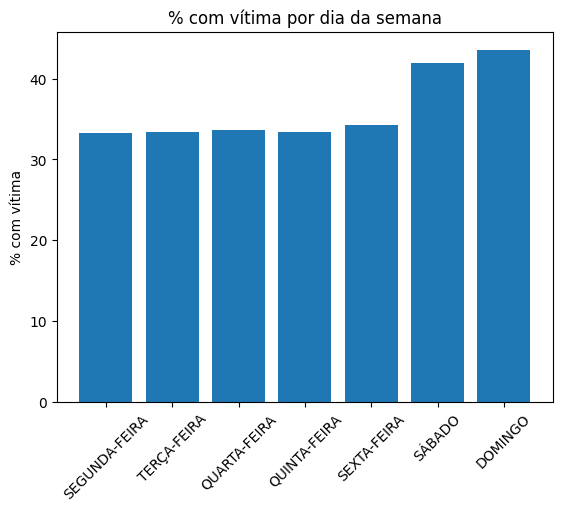

In [ ]:
# fim de semana (0 = dia útil, 1 = fim de semana)
pct_fim_de_semana = df.groupby("fim_de_semana")["vitima"].mean() * 100
pct_fim_de_semana = pct_fim_de_semana.round(1)
print(pct_fim_de_semana)

# cada dia da semana, na ordem certa
dias = ["SEGUNDA-FEIRA", "TERÇA-FEIRA", "QUARTA-FEIRA", "QUINTA-FEIRA", "SEXTA-FEIRA", "SÁBADO", "DOMINGO"]
pct_dias = []
for dia in dias:
    acidentes_do_dia = df[df["dia_sem"] == dia]
    pct = round(acidentes_do_dia["vitima"].mean() * 100, 1)
    pct_dias.append(pct)
    print(f"{dia}: {pct}%")

plt.bar(dias, pct_dias)
plt.title("% com vítima por dia da semana")
plt.ylabel("% com vítima")
plt.xticks(rotation=45)
plt.show()

### 6.5 Por horário

hora_cheia
0     46.9
1     47.8
2     45.4
3     41.7
4     39.3
5     41.9
6     39.0
7     37.3
8     32.1
9     28.5
10    25.9
11    28.1
12    32.6
13    33.5
14    30.3
15    29.8
16    32.3
17    33.2
18    39.6
19    44.9
20    47.4
21    52.3
22    49.7
23    50.1
Name: vitima, dtype: float64


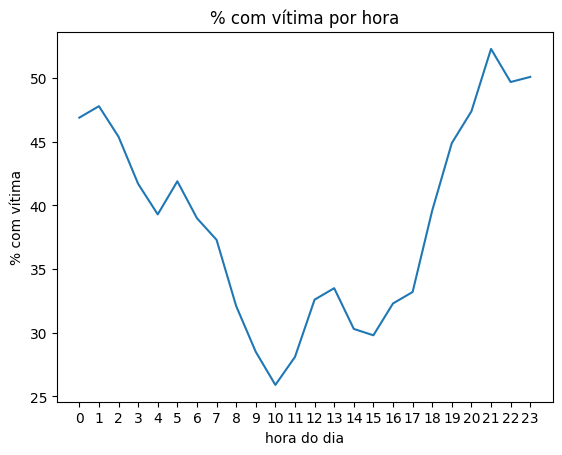

In [ ]:
pct_hora = df.groupby("hora_cheia")["vitima"].mean() * 100
pct_hora = pct_hora.round(1)
print(pct_hora)

plt.plot(pct_hora.index, pct_hora.values)
plt.xticks(range(0, 24))
plt.title("% com vítima por hora")
plt.xlabel("hora do dia")
plt.ylabel("% com vítima")
plt.show()

### 6.6 Por região

regiao
CENTRO    26.8
LESTE     35.4
NORTE     35.3
SUL       40.1
Name: vitima, dtype: float64


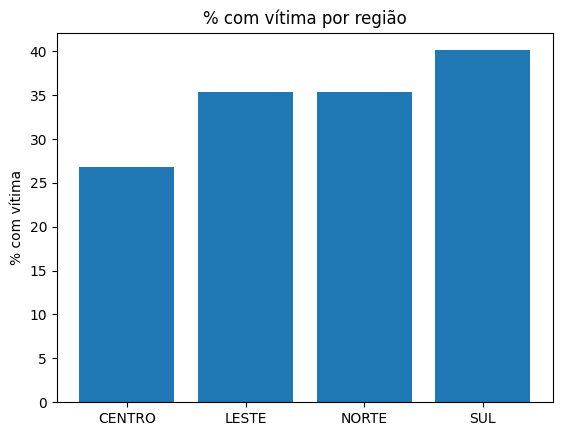

In [ ]:
pct_regiao = df.groupby("regiao")["vitima"].mean() * 100
pct_regiao = pct_regiao.round(1)
print(pct_regiao)

plt.bar(pct_regiao.index, pct_regiao.values)
plt.title("% com vítima por região")
plt.ylabel("% com vítima")
plt.show()

### 6.7 Por ano
**Atenção:** 2026 é parcial (dados extraídos em outubro), por isso usamos percentual e não contagem.

ano
2021    36.4
2022    35.6
2023    36.9
2024    37.3
2025    33.2
2026    32.6
Name: vitima, dtype: float64


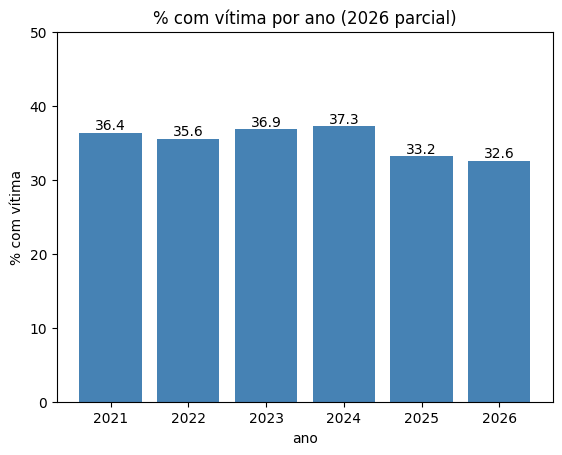

In [ ]:
pct_ano = df.groupby("ano")["vitima"].mean() * 100
pct_ano = pct_ano.round(1)
print(pct_ano)

# bar_label escreve o valor em cima de cada barra
barras = plt.bar(pct_ano.index, pct_ano.values, color="steelblue")
plt.bar_label(barras)
plt.ylim(0, 50)
plt.xticks(pct_ano.index)
plt.title("% com vítima por ano (2026 parcial)")
plt.xlabel("ano")
plt.ylabel("% com vítima")
plt.show()

## 7. Modelo KNN (k = 5)
O KNN olha os **k acidentes mais parecidos** e decide pela maioria entre eles. A **validação cruzada** divide os dados em 5 partes, treina em 4 e testa na 5ª, repetindo 5 vezes, e a acurácia é a média.

O **chute** (dizer sempre "sem vítima") é a nota mínima que o modelo precisa superar.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import StratifiedKFold

# divide os dados em 5 partes embaralhadas, sempre do mesmo jeito
divisao = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# knn com 5 vizinhos e validação cruzada
acidente_classificador = KNeighborsClassifier(n_neighbors=5)
scores = cross_val_score(acidente_classificador, X, y, scoring="accuracy", cv=divisao)
acuracia = scores.mean()

# chute: dizer sempre "sem vítima"
chute = df[df["vitima"] == 0].shape[0] / df.shape[0]
diferenca = (acuracia - chute) * 100

print(f"KNN (k=5): {acuracia:.3f}")
print(f"Chute (sempre 'sem vítima'): {chute:.3f}")
print(f"Diferença: {diferenca:.2f} pontos percentuais")

KNN (k=5): 0.812
Chute (sempre 'sem vítima'): 0.647
Diferença: 16.50 pontos percentuais


## 8. Busca do melhor k
Testamos os valores ímpares de 1 a 29 (ímpar evita empate na votação).

vizinhos: 1  acuracia: 0.624
vizinhos: 3  acuracia: 0.776
vizinhos: 5  acuracia: 0.792
vizinhos: 7  acuracia: 0.799
vizinhos: 9  acuracia: 0.806
vizinhos: 11  acuracia: 0.825
vizinhos: 13  acuracia: 0.826
vizinhos: 15  acuracia: 0.827
vizinhos: 17  acuracia: 0.825
vizinhos: 19  acuracia: 0.827
vizinhos: 21  acuracia: 0.827
vizinhos: 23  acuracia: 0.828
vizinhos: 25  acuracia: 0.828
vizinhos: 27  acuracia: 0.827
vizinhos: 29  acuracia: 0.827
Melhor k: 23 (acurácia 0.828 | chute na amostra: 0.650)


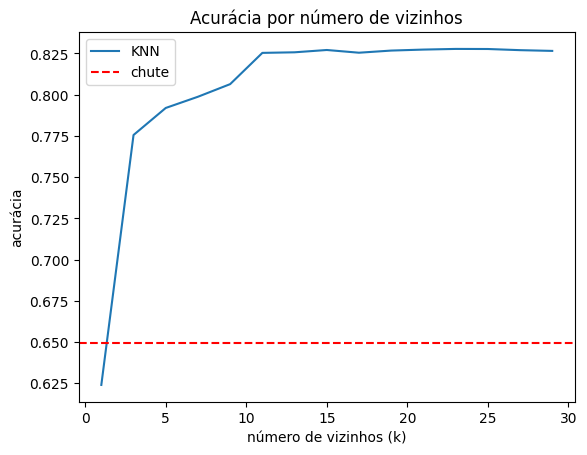

In [ ]:
# amostra de 20 mil acidentes só para a busca (com todos demora muito)
amostra = df.sample(n=20000, random_state=42)
X_amostra = amostra[veiculos + ["noite", "fim_de_semana"]]
y_amostra = amostra["vitima"]
chute_amostra = amostra[amostra["vitima"] == 0].shape[0] / amostra.shape[0]

lista_vizinhos = []
lista_acuracias = []
melhor_vizinhos = 0
melhor_acuracia = 0

for i in range(1, 30, 2):
    acidente_classificador = KNeighborsClassifier(n_neighbors=i)
    scores = cross_val_score(acidente_classificador, X_amostra, y_amostra, scoring="accuracy", cv=divisao)
    acuracia = scores.mean()
    print(f"vizinhos: {i}  acuracia: {acuracia:.3f}")

    lista_vizinhos.append(i)
    lista_acuracias.append(acuracia)

    # guarda o número de vizinhos com a maior acurácia até agora
    if acuracia > melhor_acuracia:
        melhor_acuracia = acuracia
        melhor_vizinhos = i

print(f"Melhor k: {melhor_vizinhos} (acurácia {melhor_acuracia:.3f} | chute na amostra: {chute_amostra:.3f})")

plt.plot(lista_vizinhos, lista_acuracias, label="KNN")
plt.axhline(chute_amostra, color="red", linestyle="--", label="chute")
plt.title("Acurácia por número de vizinhos")
plt.xlabel("número de vizinhos (k)")
plt.ylabel("acurácia")
plt.legend()
plt.show()

## 9. Predict com 2 acidentes inventados
- **A:** 2 autos, à noite, fim de semana
- **B:** 1 moto e 1 auto, de dia, dia útil

In [ ]:
# modelo final: melhor número de vizinhos e todos os dados
acidente_classificador = KNeighborsClassifier(n_neighbors=melhor_vizinhos)
acidente_classificador.fit(X, y)

# ordem: auto, taxi, lotacao, onibus_urb, onibus_met, onibus_int, caminhao, moto, carroca, bicicleta, patinete, noite, fim_de_semana
# A: 2 autos, à noite, no fim de semana
# B: 1 auto e 1 moto, de dia, em dia útil
novos_acidentes = pd.DataFrame([[2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1],
                                [1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0]], columns=X.columns)

previsoes = acidente_classificador.predict(novos_acidentes)
probabilidades = acidente_classificador.predict_proba(novos_acidentes)

nomes = ["A", "B"]
for i in range(2):
    if previsoes[i] == 1:
        resultado = "COM vítima"
    else:
        resultado = "SEM vítima"
    chance = probabilidades[i][1] * 100
    print(f"Acidente {nomes[i]}: {resultado} (prob. {chance:.0f}%)")

Acidente A: SEM vítima (prob. 22%)
Acidente B: COM vítima (prob. 74%)
